# Notebook 4 — Can We Do Better? Improvement Experiments

**Previous:** [Notebook 3 — Modeling and evaluation](3_modeling_and_evaluation.ipynb)

Notebook 3 ended with an honest negative result: the selected model (logistic regression) reached a test ROC-AUC of
about 0.52, no better than the persistence rule. This notebook tests **four ideas for improving the prediction**, chosen
from the diagnosis in Notebook 3 and from the bond-forecasting literature:

| # | Idea | Why it might help |
|---|---|---|
| E1 | **Predict big moves only** (±15 bp or more) | Small moves are close to random noise; teaching the model only on clear moves may sharpen the signal |
| E2 | **Use history back to 1962** | 2006–2022 was almost entirely a falling-rate era; 1962–1981 adds a long *rising*-rate era the model has never seen |
| E3 | **Add information not already in market prices** | Term premium, inflation momentum, jobless claims and financial conditions |
| E4 | **Weight recent years more heavily** | Markets change; recent behaviour may be more relevant |

Section 10 then asks a different question: if direction is so hard to predict, is the **size** of the next move
predictable?

### Ground rules (so we do not fool ourselves)

1. **The 2022–26 test set is not touched until Section 8.** Every idea is screened with **walk-forward validation**
   inside the training period: for each year from 2008 to 2021, train on all earlier data (with a 21-day gap) and
   predict that year. This mimics using the model in real time.
2. **Every idea uses the same simple model** (L2-regularised logistic regression, `C = 0.1`, fixed in advance), so
   differences come from the idea, not from tuning.
3. **Every variant tried is logged** in the experiment table, including the ones that fail.
4. **The winning configuration is chosen by a rule fixed in advance**: highest walk-forward ROC-AUC on all days.
5. Only then is that single configuration evaluated **once** on the 2022–26 test set.

## 1. Setup and data

In [10]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

DATA_DIR = Path("../data")
PROCESSED_DIR = DATA_DIR / "processed"
IMG_DIR = Path("../images")
HORIZON = 21               # trading days ahead
BIG_MOVE_BP = 15           # threshold for a "big move" (E1)
VALIDATION_YEARS = range(2008, 2022)        # walk-forward validation years (inside the training period)
TEST_START, TEST_END = "2022-06-10", "2026-09-09"  # same test window as Notebook 3


def read_fred_csv(path):
    return pd.read_csv(path, parse_dates=["observation_date"], index_col="observation_date", na_values=[".", ""])


# Read every raw FRED file and join on date (same approach as Notebook 1)
raw_files = sorted(p for p in DATA_DIR.rglob("*.csv") if PROCESSED_DIR not in p.parents)
frames = [read_fred_csv(p) for p in raw_files]
for p, f in zip(raw_files, frames):
    print(f"{str(p.relative_to(DATA_DIR)):<36} {f.index.min():%Y-%m-%d} to {f.index.max():%Y-%m-%d}  "
          f"{', '.join(f.columns)}")
raw = pd.concat(frames, axis=1).sort_index()
raw = raw.loc[:, ~raw.columns.duplicated()]

raw/cpi_monthly.csv                  1947-01-01 to 2026-09-01  CPIAUCSL
raw/fed_funds_daily.csv              1954-07-01 to 2026-10-08  DFF
raw/financial_conditions_weekly.csv  1971-01-08 to 2026-10-09  NFCI
raw/jobless_claims_weekly.csv        1967-01-07 to 2026-10-10  ICSA
raw/market_controls_daily.csv        1987-05-20 to 2026-10-09  T10YIE, DCOILBRENTEU, DTWEXBGS
raw/term_premium_daily.csv           1990-01-02 to 2026-10-09  THREEFYTP10
raw/treasury_yields_daily.csv        1962-01-02 to 2026-10-08  DGS1MO, DGS3MO, DGS6MO, DGS1, DGS2, DGS3, DGS5, DGS7, DGS10, DGS20, DGS30
raw/vix_daily.csv                    1990-01-02 to 2026-10-09  VIXCLS


/var/folders/1q/ln4s0yr13jbbz7f07j04lx1r0000gn/T/ipykernel_77036/79290710.py:37: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  raw = pd.concat(frames, axis=1).sort_index()


### Building a long-history dataset (1962 onwards)

Only some series go back to the 1960s: the **1-, 3-, 5- and 10-year yields** (from 1962) and the **fed funds rate**
(from 1954). The 3-month bill starts in 1981, the 2-year in 1976, and the 20-year has a gap in 1987–93. So the long
dataset uses a **reduced curve: 1Y, 3Y, 5Y and 10Y**, and the features are rebuilt from those. We apply the same
cleaning rules as Notebook 1: Treasury trading days only, and forward-fill of at most 5 days.

In [11]:
curve = raw.loc[raw["DGS10"].notna(), ["DGS1", "DGS3", "DGS5", "DGS10", "DFF"]].ffill(limit=5)
curve.columns = ["1Y", "3Y", "5Y", "10Y", "fed_funds"]
curve = curve.loc["1962-01-01":]
y10 = curve["10Y"]

long = pd.DataFrame(index=curve.index)
long["level_10y_vs_1y"] = y10 - y10.rolling(252).mean()
long["slope_10y_1y"] = curve["10Y"] - curve["1Y"]
long["butterfly_1s5s10s"] = 2 * curve["5Y"] - curve["1Y"] - curve["10Y"]
long["mom_10y_21d"] = (y10 - y10.shift(21)) * 100
long["mom_10y_63d"] = (y10 - y10.shift(63)) * 100
long["vol_10y_21d"] = (y10.diff() * 100).rolling(21).std()
long["spread_10y_fedfunds"] = y10 - curve["fed_funds"]
long["fedfunds_chg_63d"] = (curve["fed_funds"] - curve["fed_funds"].shift(63)) * 100
LONG_FEATURES = list(long.columns)

long["fwd_chg_10y_bp"] = (y10.shift(-HORIZON) - y10) * 100
long = long.dropna(subset=LONG_FEATURES + ["fwd_chg_10y_bp"])
long["target_up"] = (long["fwd_chg_10y_bp"] > 0).astype(int)
print(f"Long dataset: {len(long):,} days, {long.index.min():%Y-%m-%d} to {long.index.max():%Y-%m-%d}, "
      f"{len(LONG_FEATURES)} features")

Long dataset: 15,906 days, 1963-01-04 to 2026-09-09, 8 features


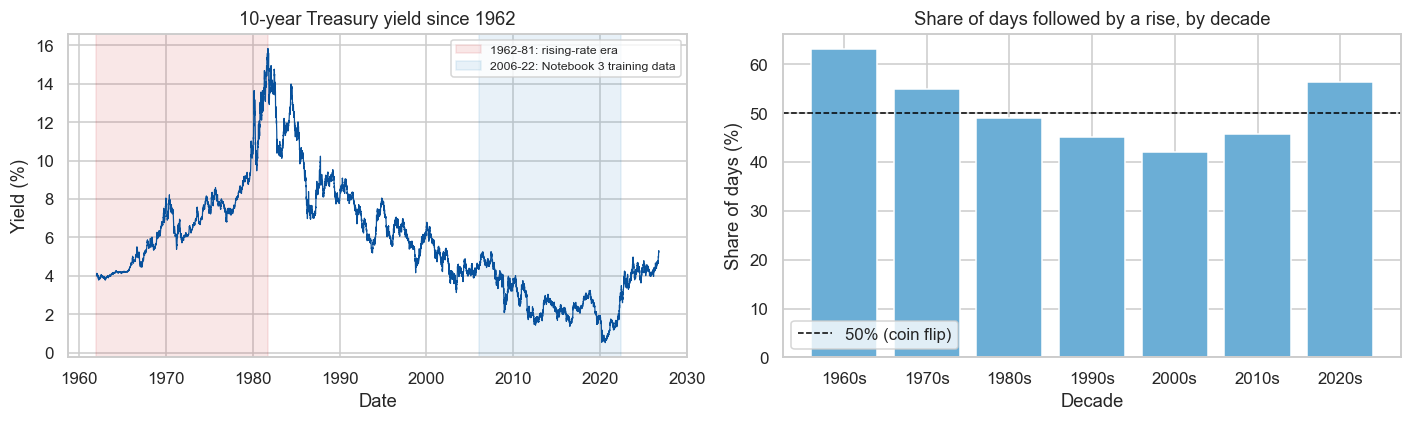

In [12]:
# How different are the eras? Share of days followed by a rise, by decade
decade_share = long.groupby((long.index.year // 10) * 10)["target_up"].mean() * 100
decade_move = long.groupby((long.index.year // 10) * 10)["fwd_chg_10y_bp"].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(y10.index, y10, color="#08519c", lw=0.8)
axes[0].axvspan(pd.Timestamp("1962-01-01"), pd.Timestamp("1981-09-30"), color="#cb181d", alpha=0.10,
                label="1962-81: rising-rate era")
axes[0].axvspan(pd.Timestamp("2006-01-01"), pd.Timestamp("2022-05-31"), color="#4292c6", alpha=0.12,
                label="2006-22: Notebook 3 training data")
axes[0].set_title("10-year Treasury yield since 1962")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Yield (%)")
axes[0].legend(loc="upper right", fontsize=8)

axes[1].bar(decade_share.index.astype(str) + "s", decade_share.values, color="#6baed6")
axes[1].axhline(50, color="black", ls="--", lw=1, label="50% (coin flip)")
axes[1].set_title("Share of days followed by a rise, by decade")
axes[1].set_xlabel("Decade")
axes[1].set_ylabel("Share of days (%)")
axes[1].legend(loc="lower left")
fig.tight_layout()
plt.show()

The 1960s and 1970s were dominated by rising yields, the opposite of the 2006–2022 sample. A model that has only
seen falling rates has never learned what a rising-rate market looks like. **E2 tests whether showing it one helps.**

### Additional information for E3 (from FRED)

| FRED series | Feature | Idea |
|---|---|---|
| `THREEFYTP10` (Kim–Wright term premium, from 1990) | Term premium minus its 1-year average | The extra yield investors demand for holding long bonds; it tends to revert to its average |
| `CPIAUCSL` (from 1947) | Change in annual inflation over 3 months, **lagged to its release date** | Is inflation speeding up or slowing down? |
| `ICSA` (weekly jobless claims, from 1967) | % change in the 4-week average over the last month | The most timely read on the labour market |
| `NFCI` (Chicago Fed financial conditions, from 1971) | Level and 1-month change | Tight financial conditions push investors towards safe Treasuries |

In [13]:
extra = pd.DataFrame(index=curve.index)

# Inflation momentum, using each CPI value only from the 15th of the following month (publication lag)
cpi = raw["CPIAUCSL"].dropna()
cpi_yoy = cpi.pct_change(12, fill_method=None) * 100
cpi_yoy.index = cpi_yoy.index + pd.offsets.MonthBegin(1) + pd.Timedelta(days=14)
cpi_yoy_daily = cpi_yoy.reindex(curve.index, method="ffill")
extra["cpi_yoy_chg_3m"] = cpi_yoy_daily - cpi_yoy_daily.shift(63)

# Weekly series: claims are dated to the week-ending Saturday and released the following Thursday;
# NFCI is dated to the week-ending Friday and released the following Wednesday. Shift by 6 days to be safe.
def weekly_to_daily(series, release_lag_days=6):
    s = series.dropna()
    s.index = s.index + pd.Timedelta(days=release_lag_days)
    return s.reindex(curve.index, method="ffill")

claims_4wk = weekly_to_daily(raw["ICSA"].dropna().rolling(4).mean())
extra["claims_chg_1m"] = claims_4wk.pct_change(21, fill_method=None) * 100
nfci = weekly_to_daily(raw["NFCI"])
extra["nfci"] = nfci
extra["nfci_chg_1m"] = nfci - nfci.shift(21)

# Term premium (daily, from 1990)
tp = raw["THREEFYTP10"].reindex(curve.index).ffill(limit=5)
extra["term_premium_vs_1y"] = tp - tp.rolling(252).mean()

MACRO_FEATURES = ["cpi_yoy_chg_3m", "claims_chg_1m", "nfci", "nfci_chg_1m"]
TP_FEATURES = ["term_premium_vs_1y"]
long = long.join(extra)
print("First date each new feature is available:")
print(long[MACRO_FEATURES + TP_FEATURES].apply(lambda s: s.first_valid_index().date()).to_string())

First date each new feature is available:
cpi_yoy_chg_3m        1963-01-04
claims_chg_1m         1967-03-08
nfci                  1971-01-14
nfci_chg_1m           1971-02-16
term_premium_vs_1y    1991-01-03


## 2. The walk-forward evaluator

For each validation year *Y* from 2008 to 2021:
1. **Train** on every day from the chosen start date up to the start of *Y*, minus a 21-day gap, so no training
   outcome overlaps year *Y*.
2. **Predict** every day in year *Y*.

All predictions are then pooled and scored. Every experiment therefore faces **exactly the same 14 years of unseen
days**, which makes the comparisons fair.

In [15]:
def make_model():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))


def walk_forward(data, features, start="1962-01-01", big_moves_only=False, half_life_years=None,
                 years=VALIDATION_YEARS):
    # Returns a DataFrame of out-of-sample predictions for every day in the evaluation years
    data = data.loc[start:].dropna(subset=features + ["fwd_chg_10y_bp"])
    out = []
    for year in years:
        test_mask = data.index.year == year
        cutoff = data.index[test_mask][0]
        train = data.loc[: cutoff].iloc[: -(HORIZON + 1)]       # purge the last HORIZON days before the year
        if big_moves_only:
            train = train[train["fwd_chg_10y_bp"].abs() >= BIG_MOVE_BP]
        weights = None
        if half_life_years:
            age_years = (cutoff - train.index).days / 365.25
            weights = 0.5 ** (age_years / half_life_years)
        model = make_model()
        model.fit(train[features], train["target_up"], logisticregression__sample_weight=weights)
        test = data.loc[test_mask]
        out.append(pd.DataFrame({"proba": model.predict_proba(test[features])[:, 1],
                                 "y": test["target_up"], "move": test["fwd_chg_10y_bp"],
                                 "momentum": test["mom_10y_21d"]}, index=test.index))
    return pd.concat(out)


def score(pred):
    big = pred["move"].abs() >= BIG_MOVE_BP
    return {"ROC-AUC (all days)": roc_auc_score(pred["y"], pred["proba"]),
            "accuracy (all days)": accuracy_score(pred["y"], pred["proba"] >= 0.5),
            "ROC-AUC (big moves)": roc_auc_score(pred.loc[big, "y"], pred.loc[big, "proba"]),
            "persistence accuracy": accuracy_score(pred["y"], pred["momentum"] > 0)}


experiment_log = []


def run(name, data, features, **kwargs):
    pred = walk_forward(data, features, **kwargs)
    result = {"experiment": name, **score(pred)}
    experiment_log.append(result)
    print(f"{name:<58} AUC all {result['ROC-AUC (all days)']:.3f} | "
          f"AUC big moves {result['ROC-AUC (big moves)']:.3f}")
    return pred

## 3. E0 — Baseline: reproduce Notebook 3's set-up

Notebook 3's 15 features, data from 2006 onwards. This is the bar every idea must clear. A second baseline uses the
**reduced long-history feature set from the same start date**, so E2 can isolate the effect of *more history* from the
effect of *different features*.

In [16]:
nb3 = pd.read_csv(PROCESSED_DIR / "model_dataset.csv", index_col=0, parse_dates=True)
NB3_FEATURES = [c for c in nb3.columns if c not in ("fwd_chg_10y_bp", "target_up")]

pred_e0 = run("E0  Baseline: Notebook 3 features, data from 2006", nb3, NB3_FEATURES, start="2006-01-01")
pred_e0b = run("E0b Simpler: 8 curve & policy features, data from 2001", long, LONG_FEATURES, start="2001-08-01")

E0  Baseline: Notebook 3 features, data from 2006          AUC all 0.529 | AUC big moves 0.524
E0b Simpler: 8 curve & policy features, data from 2001     AUC all 0.563 | AUC big moves 0.546


## 4. E1 — Predict big moves only

The model is **trained only on days followed by a move of at least 15 bp** (about half of all days), but it still
makes a prediction **every** day. The aim is to learn from clear signals rather than noise.

In [17]:
pred_e1 = run("E1  Big-move training, Notebook 3 features, from 2006", nb3, NB3_FEATURES, start="2006-01-01",
              big_moves_only=True)

E1  Big-move training, Notebook 3 features, from 2006      AUC all 0.541 | AUC big moves 0.539


## 5. E2 — Train on history back to 1962

In [18]:
pred_e2 = run("E2  Simpler features, data from 1962", long, LONG_FEATURES, start="1962-01-01")
pred_e2b = run("E2b Data from 1962 + big-move training", long, LONG_FEATURES, start="1962-01-01",
               big_moves_only=True)

E2  Simpler features, data from 1962                       AUC all 0.553 | AUC big moves 0.530
E2b Data from 1962 + big-move training                     AUC all 0.547 | AUC big moves 0.513


## 6. E3 — Add information not already in market prices

The macro features begin in 1971, so these runs start in 1972 (the 1-year averages need a year to warm up). The term
premium starts in 1990, so that run starts in 1991. Each has a **same-start control without the new features**, so we
measure only what the new information adds.

In [19]:
run("E3c Control: simpler features, data from 1972", long, LONG_FEATURES, start="1972-01-01")
pred_e3 = run("E3  + macro (inflation, claims, financial conditions), from 1972", long,
              LONG_FEATURES + MACRO_FEATURES, start="1972-01-01")
run("E3d Control: simpler features, data from 1991", long, LONG_FEATURES, start="1991-01-01")
pred_e3tp = run("E3b + macro + term premium, from 1991", long,
                LONG_FEATURES + MACRO_FEATURES + TP_FEATURES, start="1991-01-01")

E3c Control: simpler features, data from 1972              AUC all 0.528 | AUC big moves 0.496
E3  + macro (inflation, claims, financial conditions), from 1972 AUC all 0.520 | AUC big moves 0.513
E3d Control: simpler features, data from 1991              AUC all 0.538 | AUC big moves 0.514
E3b + macro + term premium, from 1991                      AUC all 0.528 | AUC big moves 0.497


## 7. E4 — Weight recent years more heavily

Using the full 1962 history, sample weights halve every *N* years, so the model leans on recent behaviour but still learns from the rising-rate era.

In [20]:
for half_life in (5, 10):
    run(f"E4  Data from 1962, half-life {half_life} years", long, LONG_FEATURES,
        start="1962-01-01", half_life_years=half_life)

E4  Data from 1962, half-life 5 years                      AUC all 0.532 | AUC big moves 0.495
E4  Data from 1962, half-life 10 years                     AUC all 0.536 | AUC big moves 0.501


## 8. Experiment log and choice of the winner

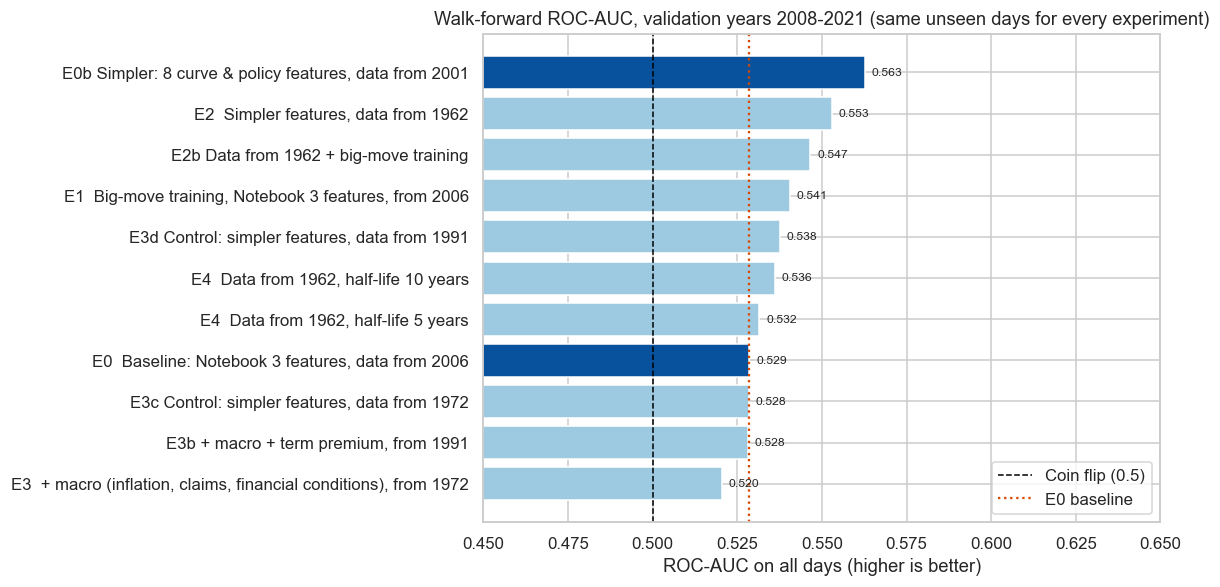

,ROC-AUC (all days),accuracy (all days),ROC-AUC (big moves),persistence accuracy,gain vs E0 (AUC points)
experiment,,,,,
"E0 Baseline: Notebook 3 features, data from 2006",0.529,0.523,0.524,0.499,0.000
"E0b Simpler: 8 curve & policy features, data from 2001",0.563,0.551,0.546,0.499,3.402
"E1 Big-move training, Notebook 3 features, from 2006",0.541,0.551,0.539,0.499,1.200
"E2 Simpler features, data from 1962",0.553,0.552,0.530,0.499,2.428
E2b Data from 1962 + big-move training,0.547,0.517,0.513,0.499,1.799
"E3c Control: simpler features, data from 1972",0.528,0.526,0.496,0.499,-0.019
"E3 + macro (inflation, claims, financial conditions), from 1972",0.520,0.501,0.513,0.499,-0.813
"E3d Control: simpler features, data from 1991",0.538,0.521,0.514,0.499,0.903
"E3b + macro + term premium, from 1991",0.528,0.524,0.497,0.499,-0.056


In [21]:
log = pd.DataFrame(experiment_log).set_index("experiment")
baseline_auc = log.iloc[0]["ROC-AUC (all days)"]
log["gain vs E0 (AUC points)"] = (log["ROC-AUC (all days)"] - baseline_auc) * 100

fig, ax = plt.subplots(figsize=(11, 5.5))
ordered = log.sort_values("ROC-AUC (all days)")
colors = ["#08519c" if name.startswith("E0") else "#9ecae1" for name in ordered.index]
ax.barh(ordered.index, ordered["ROC-AUC (all days)"], color=colors)
ax.axvline(0.5, color="black", ls="--", lw=1, label="Coin flip (0.5)")
ax.axvline(baseline_auc, color="#d94801", ls=":", lw=1.5, label="E0 baseline")
for i, v in enumerate(ordered["ROC-AUC (all days)"]):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlim(0.45, max(0.65, ordered["ROC-AUC (all days)"].max() + 0.03))
ax.set_title("Walk-forward ROC-AUC, validation years 2008-2021 (same unseen days for every experiment)")
ax.set_xlabel("ROC-AUC on all days (higher is better)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(IMG_DIR / "12_experiment_log.png", bbox_inches="tight")
plt.show()
log.round(3)

In [22]:
# Pre-registered rule: the experiment (excluding the E3c/E3d controls) with the highest walk-forward AUC on all days
candidates = log[~log.index.str.startswith(("E3c", "E3d"))]
WINNER = candidates["ROC-AUC (all days)"].idxmax()
print("Winner:", WINNER)
print(f"Walk-forward AUC {candidates.loc[WINNER, 'ROC-AUC (all days)']:.3f} vs baseline {baseline_auc:.3f}")

Winner: E0b Simpler: 8 curve & policy features, data from 2001
Walk-forward AUC 0.563 vs baseline 0.529


**Reading the result.**

- **Simpler beat richer.** The 8-feature model (curve slope and curvature from 1Y/5Y/10Y, momentum, volatility, and
  the policy-rate spread) scored **0.563** against **0.529** for Notebook 3's 15 features on exactly the same unseen
  days. The dropped features (VIX, oil, the dollar, breakeven inflation) added more noise than signal.
- **Training on big moves helped a little** with Notebook 3's features (0.529 → 0.541), but not with the simpler set.
- **More history did not help.** Going back to 1962 (0.553) was slightly *worse* than starting in 2001 (0.563), and
  weighting recent years did not rescue it (0.532–0.536). The 1960s–70s rising-rate market seems to have behaved
  differently enough that it adds as much confusion as information.
- **New macro information did not help.** Inflation momentum, jobless claims and financial conditions *lowered* the
  score against their same-start control (0.520 vs 0.528), and the term premium added nothing (0.528 vs 0.538).
  Sensible economic stories do not automatically translate into one-month predictive power.
- All differences are a few AUC points. The winner is chosen by the pre-agreed rule, and the test below checks it
  **once**.

## 9. One-time check on the 2022–26 test set

The winning configuration is now run **once** on the same test window as Notebook 3, retrained at the start of every
test year on all earlier data (walk-forward). It is compared with Notebook 3's selected model and with persistence.

In [23]:
WINNER_CONFIGS = {
    "E0  Baseline: Notebook 3 features, data from 2006": (nb3, NB3_FEATURES, dict(start="2006-01-01")),
    "E1  Big-move training, Notebook 3 features, from 2006": (nb3, NB3_FEATURES, dict(start="2006-01-01", big_moves_only=True)),
    "E0b Simpler: 8 curve & policy features, data from 2001": (long, LONG_FEATURES, dict(start="2001-08-01")),
    "E2  Simpler features, data from 1962": (long, LONG_FEATURES, dict(start="1962-01-01")),
    "E2b Data from 1962 + big-move training": (long, LONG_FEATURES, dict(start="1962-01-01", big_moves_only=True)),
    "E3  + macro (inflation, claims, financial conditions), from 1972": (long, LONG_FEATURES + MACRO_FEATURES, dict(start="1972-01-01")),
    "E3b + macro + term premium, from 1991": (long, LONG_FEATURES + MACRO_FEATURES + TP_FEATURES, dict(start="1991-01-01")),
    "E4  Data from 1962, half-life 5 years": (long, LONG_FEATURES, dict(start="1962-01-01", half_life_years=5)),
    "E4  Data from 1962, half-life 10 years": (long, LONG_FEATURES, dict(start="1962-01-01", half_life_years=10)),
}
data_w, features_w, kwargs_w = WINNER_CONFIGS[WINNER]

test_years = range(2022, 2027)
pred_test = walk_forward(data_w, features_w, years=test_years, **kwargs_w).loc[TEST_START:TEST_END]
pred_base = walk_forward(nb3, NB3_FEATURES, start="2006-01-01", years=test_years).loc[TEST_START:TEST_END]
nb3_results = pd.read_csv(PROCESSED_DIR / "model_comparison.csv", index_col=0)

final = pd.DataFrame([
    {"model": f"Winner: {WINNER.split('  ')[-1]}", **score(pred_test)},
    {"model": "E0 baseline, re-fitted every year", **score(pred_base)},
]).set_index("model")
final["test days"] = len(pred_test)
print(f"Notebook 3 selected model (fitted once in 2022): test ROC-AUC "
      f"{nb3_results.loc['Logistic Regression', 'test ROC-AUC']:.3f}, "
      f"accuracy {nb3_results.loc['Logistic Regression', 'test accuracy']:.3f}")
final.round(3)

Notebook 3 selected model (fitted once in 2022): test ROC-AUC 0.520, accuracy 0.512


,ROC-AUC (all days),accuracy (all days),ROC-AUC (big moves),persistence accuracy,test days
model,,,,,
"Winner: E0b Simpler: 8 curve & policy features, data from 2001",0.575,0.520,0.614,0.510,1061
"E0 baseline, re-fitted every year",0.519,0.527,0.503,0.515,1061


### How sure can we be? A block-bootstrap confidence interval

Consecutive test days are not independent (they share most of their 21-day outcome window), so we resample the test
period in **21-day blocks**, 2,000 times, and recompute the ROC-AUC of both models each time.

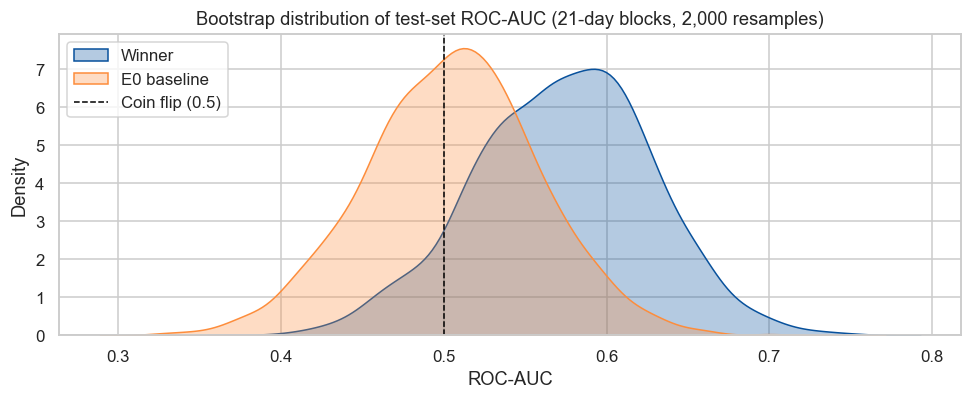

,5th percentile,median,95th percentile,share of resamples above 0.5
Winner,0.479,0.575,0.659,0.910
E0 baseline,0.415,0.507,0.594,0.546


In [24]:
def block_bootstrap_auc(pred, n_boot=2000, block=HORIZON, seed=42):
    rng = np.random.default_rng(seed)
    starts = np.arange(0, len(pred) - block + 1)
    n_blocks = int(np.ceil(len(pred) / block))
    y, p = pred["y"].to_numpy(), pred["proba"].to_numpy()
    aucs = []
    for _ in range(n_boot):
        idx = np.concatenate([np.arange(s, s + block) for s in rng.choice(starts, n_blocks)])
        if y[idx].min() != y[idx].max():
            aucs.append(roc_auc_score(y[idx], p[idx]))
    return np.array(aucs)

boot = pd.DataFrame({"Winner": block_bootstrap_auc(pred_test), "E0 baseline": block_bootstrap_auc(pred_base)})
ci = boot.quantile([0.05, 0.5, 0.95]).T
ci.columns = ["5th percentile", "median", "95th percentile"]
ci["share of resamples above 0.5"] = (boot > 0.5).mean()

fig, ax = plt.subplots(figsize=(9, 3.8))
for col, colour in zip(boot.columns, ["#08519c", "#fd8d3c"]):
    sns.kdeplot(boot[col], ax=ax, fill=True, alpha=0.3, color=colour, label=col)
ax.axvline(0.5, color="black", ls="--", lw=1, label="Coin flip (0.5)")
ax.set_title("Bootstrap distribution of test-set ROC-AUC (21-day blocks, 2,000 resamples)")
ax.set_xlabel("ROC-AUC")
ax.set_ylabel("Density")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()
ci.round(3)

### Is it useful when it is confident?

A model does not need to call every month. Here we look only at days when the predicted probability is far from 50%,
and use **non-overlapping months** (one day every 21) so each observation is independent.

In [25]:
monthly = pred_test.iloc[::HORIZON]
rows = []
for band in (0.0, 0.05, 0.10):
    confident = monthly[(monthly["proba"] - 0.5).abs() >= band]
    rows.append({"confidence band": f"|p - 0.5| >= {band:.2f}", "months": len(confident),
                 "share of months": len(confident) / len(monthly),
                 "hit rate": accuracy_score(confident["y"], confident["proba"] >= 0.5) if len(confident) else np.nan,
                 "persistence hit rate": accuracy_score(confident["y"], confident["momentum"] > 0) if len(confident) else np.nan})
pd.DataFrame(rows).set_index("confidence band").round(3)

,months,share of months,hit rate,persistence hit rate
confidence band,,,,
|p - 0.5| >= 0.00,51,1.000,0.510,0.490
|p - 0.5| >= 0.05,23,0.451,0.696,0.652
|p - 0.5| >= 0.10,9,0.176,0.667,0.556


### Economic value: a simple duration rule

A bond manager holds a 10-year bond. Each month the model either says **"reduce duration"** (predicted rise,
p > 0.5) or **"stay long"**. A long position loses when yields rise, so the gain from reducing duration in a month equals
that month's rise in yield. We compare the cumulative yield move *avoided* with simply staying long all the time
(non-overlapping months, ignoring transaction costs, which would make results slightly worse).

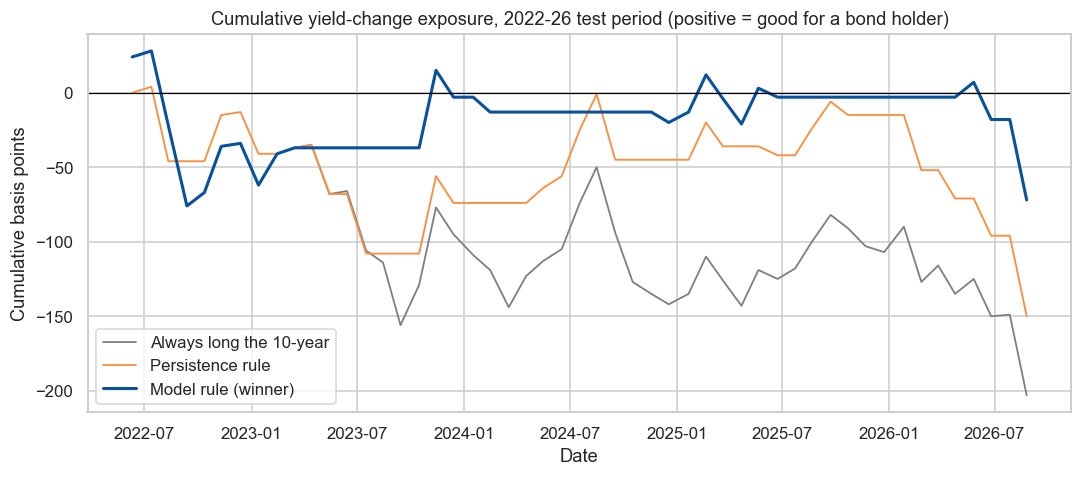

model_pnl_bp          -72.0
persistence_pnl_bp   -150.0
always_long_pnl_bp   -203.0
Name: total bp, dtype: float64

In [26]:
monthly = pred_test.iloc[::HORIZON].copy()
monthly["model_pnl_bp"] = np.where(monthly["proba"] > 0.5, 0.0, -monthly["move"])      # flat when rise predicted
monthly["persistence_pnl_bp"] = np.where(monthly["momentum"] > 0, 0.0, -monthly["move"])
monthly["always_long_pnl_bp"] = -monthly["move"]

fig, ax = plt.subplots(figsize=(10, 4.5))
for col, label, colour in [("always_long_pnl_bp", "Always long the 10-year", "grey"),
                           ("persistence_pnl_bp", "Persistence rule", "#fd8d3c"),
                           ("model_pnl_bp", "Model rule (winner)", "#08519c")]:
    ax.plot(monthly.index, monthly[col].cumsum(), label=label, color=colour, lw=2 if "Model" in label else 1.2)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Cumulative yield-change exposure, 2022-26 test period (positive = good for a bond holder)")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative basis points")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(IMG_DIR / "13_duration_rule.png", bbox_inches="tight")
plt.show()
monthly[["model_pnl_bp", "persistence_pnl_bp", "always_long_pnl_bp"]].sum().round(0).rename("total bp")

## 10. What *is* predictable: the size of next month's move

Every experiment above tried to predict the **direction** of the next move. Here we ask a different question of the
same 10-year data: does the past month tell us **how much** the yield is likely to move next month, whichever way?

For each day we measure:
- **Past volatility:** the standard deviation of daily 10-year changes over the previous 21 trading days.
- **Next-month volatility:** the same measure over the following 21 trading days.
- **Next-month move:** the change in the 10-year yield over the following 21 trading days.

This is descriptive analysis, not a fitted model, so there is nothing to over-fit. To check the pattern is not a
one-period accident, it is measured separately on the training period (2001–May 2022) and on the test period
(June 2022–2026).

In [27]:
y10_daily = curve.loc["2001-08-01":, "10Y"]
chg_bp = y10_daily.diff() * 100

vol = pd.DataFrame({
    "past_vol": chg_bp.rolling(21).std(),
    "next_vol": chg_bp[::-1].rolling(21).std()[::-1].shift(-1),    # days t+1 ... t+21
    "past_move": (y10_daily - y10_daily.shift(21)) * 100,
    "next_move": (y10_daily.shift(-21) - y10_daily) * 100,
}).dropna()
vol["next_rise"] = (vol["next_move"] > 0).astype(int)

periods = {"Full sample (2001-2026)": vol, "Training period (2001-May 2022)": vol.loc[:"2022-05-31"],
           "Test period (Jun 2022-2026)": vol.loc["2022-06-01":]}
corr_table = pd.DataFrame({
    name: {"Direction: past 1-month move vs next 1-month move": d["past_move"].corr(d["next_move"]),
           "Size: past volatility vs next-month volatility": d["past_vol"].corr(d["next_vol"])}
    for name, d in periods.items()}).T
corr_table.round(2)

,Direction: past 1-month move vs next 1-month move,Size: past volatility vs next-month volatility
Full sample (2001-2026),0.03,0.64
Training period (2001-May 2022),0.04,0.64
Test period (Jun 2022-2026),-0.05,0.57


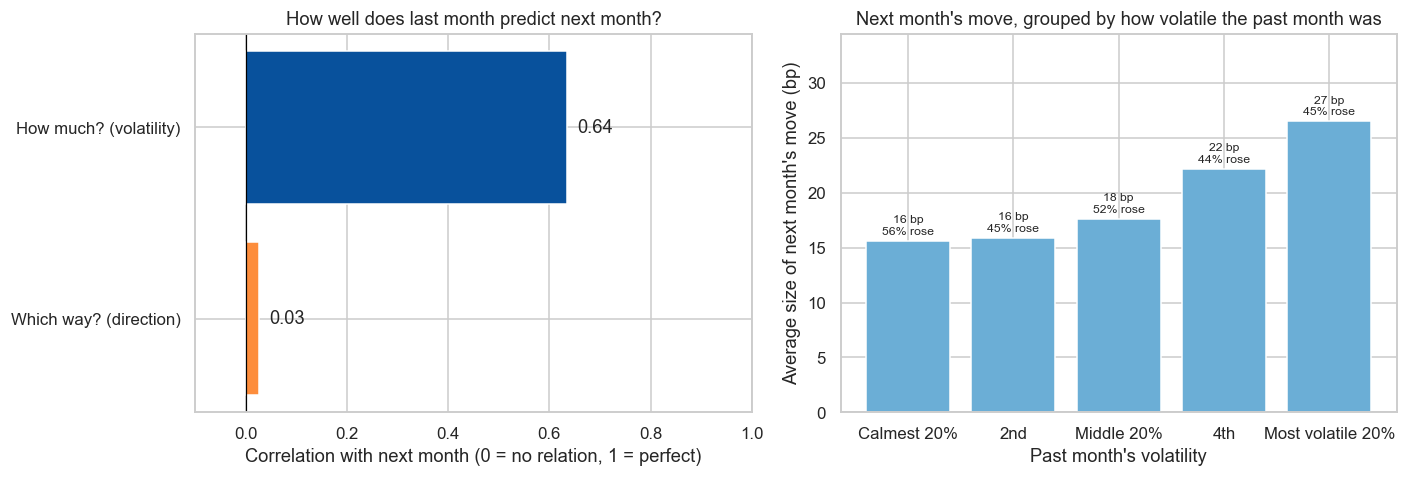

,days,avg_size_next_move_bp,share_next_month_rises
past_vol_group,,,
Calmest 20%,1252,15.61,0.56
2nd,1251,15.92,0.45
Middle 20%,1251,17.64,0.52
4th,1251,22.20,0.44
Most volatile 20%,1252,26.52,0.45


In [28]:
vol["past_vol_group"] = pd.qcut(vol["past_vol"], 5, labels=["Calmest 20%", "2nd", "Middle 20%", "4th",
                                                           "Most volatile 20%"])
by_group = vol.groupby("past_vol_group", observed=True).agg(
    days=("next_move", "size"),
    avg_size_next_move_bp=("next_move", lambda s: s.abs().mean()),
    share_next_month_rises=("next_rise", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
full = corr_table.loc["Full sample (2001-2026)"]
axes[0].barh(["Which way? (direction)", "How much? (volatility)"],
             [full.iloc[0], full.iloc[1]], color=["#fd8d3c", "#08519c"])
for i, v in enumerate([full.iloc[0], full.iloc[1]]):
    axes[0].text(v + 0.02, i, f"{v:.2f}", va="center")
axes[0].set_xlim(-0.1, 1)
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title("How well does last month predict next month?")
axes[0].set_xlabel("Correlation with next month (0 = no relation, 1 = perfect)")

axes[1].bar(by_group.index.astype(str), by_group["avg_size_next_move_bp"], color="#6baed6")
for i, (size, share) in enumerate(zip(by_group["avg_size_next_move_bp"], by_group["share_next_month_rises"])):
    axes[1].text(i, size + 0.4, f"{size:.0f} bp\n{share:.0%} rose", ha="center", va="bottom", fontsize=8)
axes[1].set_ylim(0, by_group["avg_size_next_move_bp"].max() * 1.3)
axes[1].set_title("Next month's move, grouped by how volatile the past month was")
axes[1].set_xlabel("Past month's volatility")
axes[1].set_ylabel("Average size of next month's move (bp)")
fig.tight_layout()
fig.savefig(IMG_DIR / "14_size_vs_direction.png", bbox_inches="tight")
plt.show()
by_group.round(2)

**Interpretation.**

- **Direction is not predictable from the past month; size is.** The correlation between last month's move and next
  month's move is close to zero, but the correlation between last month's volatility and next month's volatility is
  strong, and it holds in **both** the training and the test period.
- After the most turbulent 20% of months, the next month's move was about **70% larger** than after the calmest 20%,
  while the share of rises stayed close to a coin flip in every group. Volatile periods cluster together ("volatility
  clustering"), even though their direction cannot be called.
- **Why this matters in practice:** position sizes, risk limits, margins and hedge ratios can be scaled to expected
  volatility. If direction cannot be predicted, knowing *when* an unhedged position is most dangerous is the next most
  useful thing.

## 11. Conclusions

1. **The best improvement was simplification.** Cutting the model to 8 curve-and-policy features and re-fitting it
   each year raised test ROC-AUC from **0.520** (Notebook 3) to **0.575**, and to **0.614 on big-move days**. It was chosen
   by a rule fixed before the test, and the test was run once.
2. **But the evidence is suggestive, not conclusive.** The bootstrap 90% interval for the test AUC is roughly
   **0.48–0.66**, so a true AUC of 0.5 cannot be ruled out (about 9% of resamples fall below it). Overall accuracy
   moved only slightly (52% vs 51% for persistence): the model ranks months better, but its 50% cut-off is not much
   sharper.
3. **Confidence helps.** In the 23 of 51 test months where the model was at least 55/45 confident, it was right
   **70%** of the time (persistence: 65%). Acting only on confident calls is the practical way to use a weak signal.
   With so few months, though, this needs more data to confirm.
4. **Economic value in the test period.** A simple rule — step out of the 10-year when the model predicts a rise — would
   have avoided about **130 of the 203 bp** of yield increases a bond holder suffered from 2022 to 2026, beating
   persistence (150 bp lost). The rule was out of the market in 55% of months, so this is not just "always sit out"
   (which would have lost 0 bp in this rising-rate period — a reminder that one test period proves little).
5. **What did not work is also a finding.** More history (back to 1962), macroeconomic data, the term premium and
   recency weighting all failed to improve the walk-forward score. For a one-month horizon, the yield curve and the
   policy rate already contain most of what these public indicators say.

6. **The size of moves is predictable even though direction is not** (Section 10). Last month's volatility is
   strongly related to next month's (correlation about 0.6, in both training and test periods); last month's direction
   is not related to next month's at all. Risk can be scaled to expected volatility.

**Recommended model going forward:** the simpler 8-feature logistic regression, re-fitted each year, used only when
its probability is at least 55/45, and monitored for drift. The next most promising avenues are information that
is not already in market prices (FOMC communication scored with NLP, positioning data), and evaluating it over a
longer, multi-regime test period.